**06 | Subject-Level Cross-Validation for HARTH Classification**

**Human Movement Intelligence | Presented by: Reza Saadatyar (2026)**

**Objective:** Re-evaluate the three classical baselines across three disjoint-participant development folds. Compare fold-to-fold variation and individual-participant errors while preserving the original two-person final Test group.

**Scientific boundary:** Exploratory development-only CV, not nested CV, independent test evaluation or a full HARTH benchmark. Model comparison has already occurred on part of the development set.

**01. Imports and reusable utilities**

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Identify the repository and register shared and study-specific Python paths.
root = Path.cwd().resolve()
while not (root / "code/python/src/core/data_loading.py").is_file():
    if root.parent == root:
        raise RuntimeError("Open this notebook within human-movement-intelligence.")
    root = root.parent
sys.path.insert(0, str(root / "code/python/src"))
sys.path.insert(0, str(root / "studies/wearable_activity_recognition/src"))

# Reuse exactly the preceding stages; import only one new CV function.
from harth_data import ACTIVITY_NAMES, ensure_harth_sample, load_harth_subject
from core.signal_preprocessing import create_signal_windows
from core.feature_engineering import extract_signal_features
from core.data_splitting import split_group_indices
from core.group_cross_validation import evaluate_group_cross_validation

print("Subject-independent CV utilities ready")

Subject-independent CV utilities ready


**02. Reconstruct the documented eight-subject feature cohort**

The exact source file list, windowing parameters and deterministic features match Notebook 05. Files are reused from the local ignored cache.

In [2]:
SUBJECTS = ["S023", "S024", "S025", "S027", "S028", "S032", "S034", "S035"]
TASK_CLASSES = tuple(range(1, 9))
data_dir = root / "data/raw/harth_v2"

# Produce features and labels independently for each participant.
feature_parts, meta_parts = [], []
for subject in SUBJECTS:
    path = ensure_harth_sample(data_dir, subject=subject)
    data, channels = load_harth_subject(path, allow_unmapped_labels=True)
    windows, y, info = create_signal_windows(
        signals=data[channels].to_numpy(),
        labels=data["label"].to_numpy(),
        window_size=100, step_size=50,
        timestamps=data["timestamp"], sampling_rate=50,
        min_label_purity=1.0, subject_id=subject,
    )
    feature_parts.append(extract_signal_features(windows, channel_names=channels))
    meta_parts.append(info)
features_all = pd.concat(feature_parts, ignore_index=True)
metadata_all = pd.concat(meta_parts, ignore_index=True)
assert len(features_all) == len(metadata_all)
print("All source windows:", len(metadata_all))

Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S023.csv
HARTH subject S023: 137,646 rows, 6 sensors
Input signal: 137,646 samples, 6 channels
Candidate windows: 2,751
Retained windows: 2,567 | Shape: (2567, 6, 100)
Rejected candidates: 184
Input windows: (2567, 6, 100)
Feature matrix: (2567, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S024.csv
HARTH subject S024: 170,534 rows, 6 sensors
Input signal: 170,534 samples, 6 channels
Candidate windows: 3,409
Retained windows: 3,119 | Shape: (3119, 6, 100)
Rejected candidates: 290
Input windows: (3119, 6, 100)
Feature matrix: (3119, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S025.csv
HARTH subject S025: 231,729 rows, 6 sensors
Input signal: 231,729 samples, 6 channels
Candidate windows: 4,633
Retained windows: 4,272 | Shape: (4272, 6, 1

C:\Users\Reza\AppData\Local\Temp\ipykernel_14840\4259548068.py:9: UserWarning: Unexpected HARTH activity codes: [10, 11] (2,018 rows in S032.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(path, allow_unmapped_labels=True)


HARTH subject S032: 178,341 rows, 6 sensors
Input signal: 178,341 samples, 6 channels
Candidate windows: 3,565
Retained windows: 3,038 | Shape: (3038, 6, 100)
Rejected candidates: 527
Input windows: (3038, 6, 100)
Feature matrix: (3038, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S034.csv
HARTH subject S034: 188,202 rows, 6 sensors
Input signal: 188,202 samples, 6 channels
Candidate windows: 3,763
Retained windows: 3,351 | Shape: (3351, 6, 100)
Rejected candidates: 412
Input windows: (3351, 6, 100)
Feature matrix: (3351, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S035.csv
HARTH subject S035: 181,251 rows, 6 sensors
Input signal: 181,251 samples, 6 channels
Candidate windows: 3,624
Retained windows: 3,337 | Shape: (3337, 6, 100)
Rejected candidates: 287
Input windows: (3337, 6, 100)
Feature matrix: (3337, 3

**03. Define the same eight-class task and reserve final Test subjects**

Exclude out-of-task codes **after windowing**, never splice raw sequences across removed labels. Repeat the fixed-seed subject split from Notebook 05 before cross-validation.

In [3]:
# Audit excluded classes, then apply the fixed eight-class task definition.
eligible = metadata_all["label"].isin(TASK_CLASSES).to_numpy()
excluded = metadata_all.loc[~eligible, "label"].value_counts().sort_index()
features = features_all.loc[eligible].reset_index(drop=True)
metadata = metadata_all.loc[eligible].reset_index(drop=True)
print("Excluded source-code windows:", excluded.to_dict())

# Recreate exactly the original participant-disjoint split.
partitions = split_group_indices(
    group_ids=metadata["subject_id"].to_numpy(),
    train_fraction=0.50, validation_fraction=0.25,
    test_fraction=0.25, random_state=42,
)
development_indices = np.sort(np.concatenate([
    partitions["train"], partitions["validation"]
]))
reserved_test_indices = partitions["test"]

# Critically, the reserved test rows do NOT enter the CV feature or label arrays.
development_features = features.iloc[development_indices].to_numpy()
development_labels = metadata.iloc[development_indices]["label"].to_numpy()
development_subjects = metadata.iloc[development_indices]["subject_id"].to_numpy()
reserved_subjects = set(metadata.iloc[reserved_test_indices]["subject_id"])
assert not (set(development_subjects) & reserved_subjects)
print("Development participants:", sorted(set(development_subjects)))
print("Reserved final Test participants:", sorted(reserved_subjects))
print("Development matrix:", development_features.shape)

Excluded source-code windows: {10: 1, 13: 1018, 14: 238, 130: 78, 140: 65}
Independent groups: 8
train: 4 groups | 12,489 rows
validation: 2 groups | 6,470 rows
test: 2 groups | 5,604 rows
Development participants: ['S024', 'S025', 'S027', 'S028', 'S034', 'S035']
Reserved final Test participants: ['S023', 'S032']
Development matrix: (18959, 30)


**04. Cross-validate three fresh baselines across disjoint subjects**

Each fold refits Logistic Regression's StandardScaler on fold Train only. GroupKFold splits subjects rather than random windows. All predefined classes must be present in each training fold.

In [4]:
# Evaluate three independent subject-held-out folds using only development data.
fold_results, subject_results, summary = evaluate_group_cross_validation(
    features=development_features,
    labels=development_labels,
    group_ids=development_subjects,
    classes=TASK_CLASSES,
    n_splits=3,
    random_state=42,
)

# Display the actual model comparison and per-fold participant membership.
display(summary.round(4))
display(fold_results[[
    "fold", "model", "train_subjects", "validation_subjects",
    "validation_classes_present", "macro_f1", "balanced_accuracy",
]].round(4))

Fold 1: Train=4 subjects, Validation=2 subjects
Dummy (most frequent): Validation Macro F1 = 0.0551
Logistic Regression: Validation Macro F1 = 0.7878
Random Forest: Validation Macro F1 = 0.6853
Fold 2: Train=4 subjects, Validation=2 subjects
Dummy (most frequent): Validation Macro F1 = 0.0565


c:\Users\Reza\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


Logistic Regression: Validation Macro F1 = 0.6387
Random Forest: Validation Macro F1 = 0.7030
Fold 3: Train=4 subjects, Validation=2 subjects
Dummy (most frequent): Validation Macro F1 = 0.1031
Logistic Regression: Validation Macro F1 = 0.8036
Random Forest: Validation Macro F1 = 0.7535


,model,fold_macro_f1_mean,fold_macro_f1_sd,fold_macro_f1_min,fold_macro_f1_max,subject_macro_f1_fixed_mean,subject_macro_f1_observed_mean
0,Logistic Regression,0.7434,0.0909,0.6387,0.8036,0.6750,0.7908
1,Random Forest,0.7139,0.0354,0.6853,0.7535,0.6454,0.7691
2,Dummy (most frequent),0.0715,0.0273,0.0551,0.1031,0.0668,0.0795


,fold,model,train_subjects,validation_subjects,validation_classes_present,macro_f1,balanced_accuracy
0,1,Logistic Regression,"S024, S027, S028, S035","S025, S034",8,0.7878,0.8438
1,1,Random Forest,"S024, S027, S028, S035","S025, S034",8,0.6853,0.6788
2,1,Dummy (most frequent),"S024, S027, S028, S035","S025, S034",8,0.0551,0.1250
3,2,Random Forest,"S024, S025, S028, S034","S027, S035",6,0.7030,0.9628
4,2,Logistic Regression,"S024, S025, S028, S034","S027, S035",6,0.6387,0.9573
5,2,Dummy (most frequent),"S024, S025, S028, S034","S027, S035",6,0.0565,0.1667
6,3,Logistic Regression,"S025, S027, S034, S035","S024, S028",8,0.8036,0.9078
7,3,Random Forest,"S025, S027, S034, S035","S024, S028",8,0.7535,0.7468
8,3,Dummy (most frequent),"S025, S027, S034, S035","S024, S028",8,0.1031,0.1250


**05. Visualise variation across folds**

A mean alone hides variation when evaluation contains only two subjects per fold. Plot each fold and the cross-fold mean, while avoiding unjustified confidence intervals.

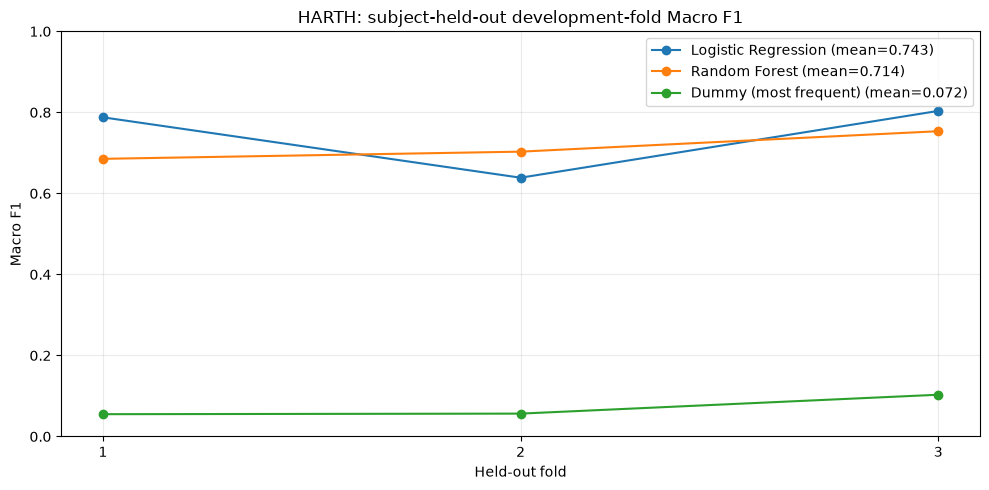

In [5]:
# Plot validation Macro F1 for each model in each subject-disjoint fold.
fig, ax = plt.subplots(figsize=(10, 5))
for model_name, table in fold_results.groupby("model", sort=False):
    table = table.sort_values("fold")
    ax.plot(
        table["fold"], table["macro_f1"], marker="o",
        label=f"{model_name} (mean={table['macro_f1'].mean():.3f})",
    )
ax.set(
    title="HARTH: subject-held-out development-fold Macro F1",
    xlabel="Held-out fold", ylabel="Macro F1",
    xticks=[1, 2, 3], ylim=(0, 1),
)
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()

**06. Compare participant-level performance**

Class availability differs across people. We show both fixed eight-class Macro F1 (same task denominator) and observed-class Macro F1 (classes present in that person's true labels). They should not be confused.

,fold,model,subject_id,windows,observed_classes,macro_f1_fixed_task,macro_f1_observed_classes
12,3,Dummy (most frequent),S024,3119,8,0.0809,0.0809
0,1,Dummy (most frequent),S025,2873,8,0.0754,0.0754
6,2,Dummy (most frequent),S027,3082,6,0.0028,0.0037
13,3,Dummy (most frequent),S028,3197,7,0.1197,0.1369
1,1,Dummy (most frequent),S034,3351,7,0.0334,0.0382
7,2,Dummy (most frequent),S035,3337,5,0.0888,0.1421
14,3,Logistic Regression,S024,3119,8,0.7825,0.7825
2,1,Logistic Regression,S025,2873,8,0.7893,0.7893
8,2,Logistic Regression,S027,3082,6,0.5705,0.7607
15,3,Logistic Regression,S028,3197,7,0.7485,0.8555


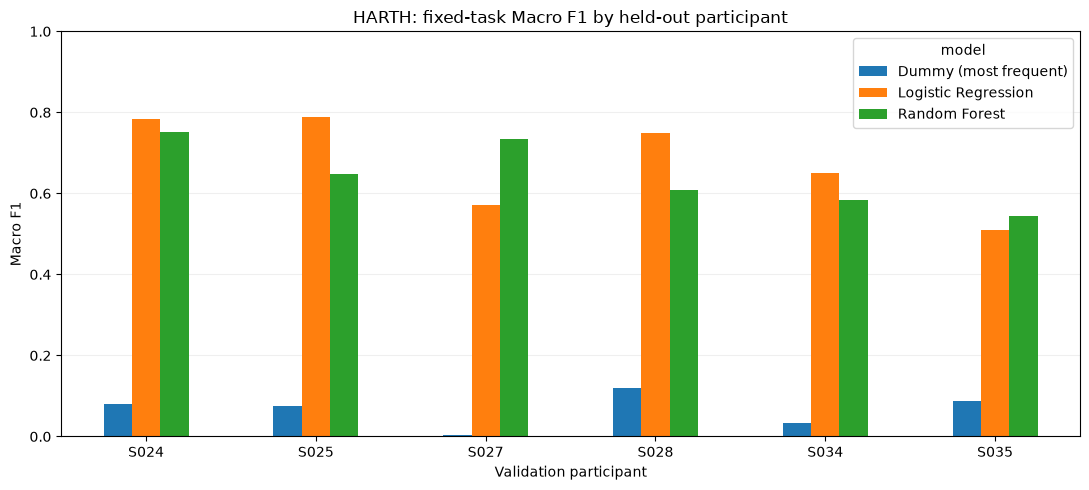

In [6]:
# Show each validation participant once per model.
display(subject_results.sort_values(["model", "subject_id"]).round(4))

# Use a horizontal bar chart to reveal person-to-person differences.
plot_data = subject_results.pivot(
    index="subject_id", columns="model", values="macro_f1_fixed_task"
).sort_index()
ax = plot_data.plot(kind="bar", figsize=(11, 5), rot=0)
ax.set(
    title="HARTH: fixed-task Macro F1 by held-out participant",
    xlabel="Validation participant", ylabel="Macro F1", ylim=(0, 1),
)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

**07. Quality gate and limitations**

This completes the development-only CV audit. We do not evaluate reserved Test subjects, train on excluded labels, or claim independent generalisation. A full-cohort protocol with more subjects and appropriately justified class coverage is still needed.

In [7]:
# Verify complete subject coverage and that reserved Test was not evaluated.
assert len(set(development_subjects)) == 6
assert set(subject_results["subject_id"]) == set(development_subjects)
assert not (set(subject_results["subject_id"]) & reserved_subjects)
assert subject_results.groupby(["model", "subject_id"]).size().eq(1).all()
assert fold_results["macro_f1"].between(0, 1).all()
assert len(fold_results) == 3 * 3

print("Development-only group CV: PASSED")
print("Reserved final Test inference: NOT PERFORMED")
print("Formal full-dataset generalisation claim: NOT SUPPORTED")

Development-only group CV: PASSED
Reserved final Test inference: NOT PERFORMED
Formal full-dataset generalisation claim: NOT SUPPORTED
